In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Load data
X, y = load_breast_cancer(return_X_y=True)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale (fit on train only to avoid data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Train
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_s, y_train)

# Evaluate
y_pred_lr = log_reg.predict(X_test_s)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Logistic Regression ROC-AUC: 0.9954


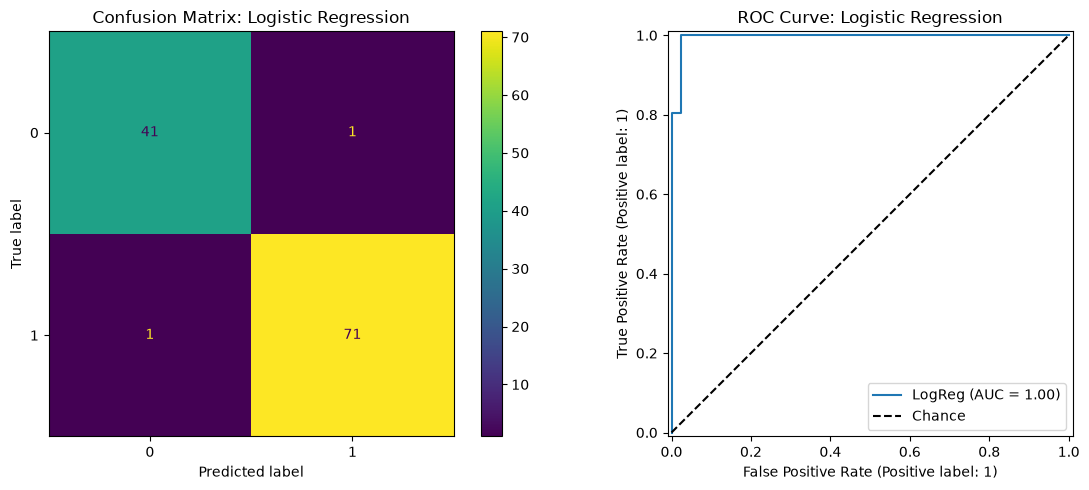

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

# Probabilities for the positive class (needed for ROC-AUC)
y_proba_lr = log_reg.predict_proba(X_test_s)[:, 1]
print("Logistic Regression ROC-AUC:", round(roc_auc_score(y_test, y_proba_lr), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=axes[0])
axes[0].set_title("Confusion Matrix: Logistic Regression")

RocCurveDisplay.from_predictions(y_test, y_proba_lr, ax=axes[1], name="LogReg")
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].set_title("ROC Curve: Logistic Regression")
axes[1].legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

              Model  Accuracy  Precision  Recall  ROC-AUC
Logistic Regression    0.9825     0.9861  0.9861   0.9954
      Random Forest    0.9561     0.9589  0.9722   0.9931


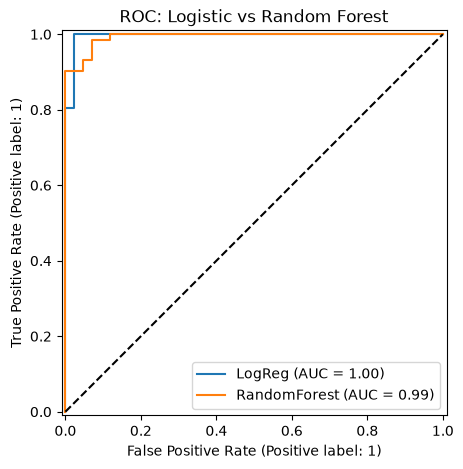

In [3]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, roc_auc_score, RocCurveDisplay)

# Train (Random Forest doesn't need scaled data)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))

# Side-by-side comparison
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy":  [accuracy_score(y_test, y_pred_lr),  accuracy_score(y_test, y_pred_rf)],
    "Precision": [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_rf)],
    "Recall":    [recall_score(y_test, y_pred_lr),    recall_score(y_test, y_pred_rf)],
    "ROC-AUC":   [roc_auc_score(y_test, y_proba_lr),  roc_auc_score(y_test, y_proba_rf)],
}).round(4)
print(results.to_string(index=False))

# ROC curves together
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_proba_lr, ax=ax, name="LogReg")
RocCurveDisplay.from_predictions(y_test, y_proba_rf, ax=ax, name="RandomForest")
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("ROC: Logistic vs Random Forest")
plt.show()

## Conclusion
On the breast cancer dataset, Logistic Regression (accuracy 0.9825, ROC-AUC 0.9954) slightly
outperformed Random Forest (accuracy 0.9561, ROC-AUC 0.9931). The dataset is clean and mostly
linearly separable, so the simpler model generalises as well as or better than the ensemble.
Results come from a single 80/20 split, so the small difference may vary with a different split.